# D3 — β sweep (d = 10)

Loads the sweep runs from `outputs/` (one experiment per β, three seeds each) and makes:

1. **Rate–distortion plot**: validation rate R (KL) against distortion D (−log p(x|z)), one point per β,
   mean ± SD over seeds, with lines of equal ELBO.
2. **Active-unit table**: a latent dimension is active if the variance over validation images of its
   encoder mean exceeds 0.01 (Burda et al., 2016).
3. **Latent traversals**: vary one latent dimension at a time around a validation image's code.

Everything uses the validation set. Figures are collected in `figures/d3_beta_sweep.pdf`,
and the table is also written to `figures/d3_active_units.csv`.

In [27]:
import csv
import json
import sys
from pathlib import Path

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# repository root: the first folder upwards that contains src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(ROOT))

from src.data import get_loaders
from src.models import build_model

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
torch.set_grad_enabled(False)          # analysis only

## Sweep runs

The folder names follow the sweep command `name=VAE_b${beta}_d10`, so the β values are written
exactly as they were passed on the command line.

In [28]:
betas = ["0.5", "1", "2", "4"]
experiments = {b: ROOT / "outputs" / f"VAE_b{b}" for b in betas}

for b, p in experiments.items():
    print(f"beta = {b:4s} {p.name:16s} exists: {p.exists()!s:5s}  seeds: {len(list(p.glob('seed_*')))}")

beta = 0.5  VAE_b0.5         exists: True   seeds: 3
beta = 1    VAE_b1           exists: True   seeds: 3
beta = 2    VAE_b2           exists: True   seeds: 3
beta = 4    VAE_b4           exists: True   seeds: 3


## Helpers

In [29]:
ACTIVE_THRESHOLD = 0.01


def seed_dirs(exp_dir):
    dirs = sorted(Path(exp_dir).glob("seed_*"))
    if not dirs:
        raise FileNotFoundError(f"no seed_* folders in {Path(exp_dir).resolve()}")
    return dirs


def load_history(run_dir):
    return json.load(open(run_dir / "history.json"))


def load_model(run_dir):
    cfg = yaml.safe_load(open(run_dir / "config.yaml"))
    model = build_model(cfg["model"])
    model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu"))
    return model.eval(), cfg


def encode(model, x):
    """Deterministic latent code: model.encode if defined, else the encoder mean."""
    if hasattr(model, "encode"):
        return model.encode(x)
    return model.encoder(x)[:, 0]


def latent_variance(model, loader):
    """Variance over all images of each latent dimension's encoder mean, shape (d,)."""
    z = torch.cat([encode(model, images) for images, _ in loader])
    return z.var(dim=0).numpy()


def mean_sd(values):
    values = np.asarray(values, dtype=float)
    sd = values.std(ddof=1, axis=0) if len(values) > 1 else np.zeros(values.shape[1:])
    return values.mean(axis=0), sd


def to_image(t):
    return t.squeeze(1).cpu().numpy()


def clean_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

In [30]:
first_run = seed_dirs(next(iter(experiments.values())))[0]
data_cfg = yaml.safe_load(open(first_run / "config.yaml"))["data"]
_, val_loader, _ = get_loaders(**data_cfg)          # the test loader is not used here
val_images, val_labels = next(iter(val_loader))

pdf = PdfPages(FIG_DIR / "d3_beta_sweep.pdf")

## 1. Rate–distortion plot

For each run, D and R are the validation values after the final epoch. Large points: mean over seeds
with ± SD error bars in both directions; small points: individual seeds.
Since ELBO = −(D + R), the dashed diagonals are lines of equal ELBO: points further down-left have a better ELBO.

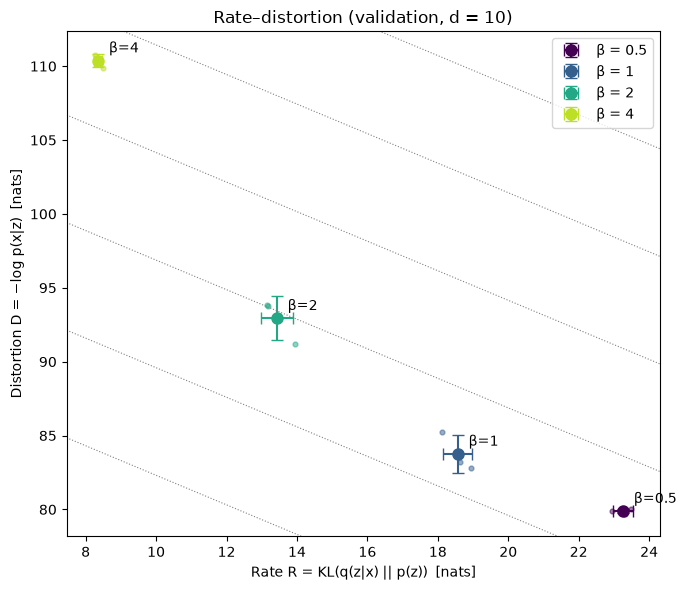

β = 0.5   D =   79.88 ±  0.15   R =  23.25 ±  0.29   −ELBO =  103.13
β = 1     D =   83.75 ±  1.28   R =  18.56 ±  0.42   −ELBO =  102.31
β = 2     D =   92.94 ±  1.49   R =  13.42 ±  0.45   −ELBO =  106.36
β = 4     D =  110.37 ±  0.43   R =   8.35 ±  0.12   −ELBO =  118.72


In [31]:
rd = {}                                               # beta -> (D per seed, R per seed)
for b, exp_dir in experiments.items():
    hs = [load_history(d) for d in seed_dirs(exp_dir)]
    rd[b] = (np.array([h["val_D"][-1] for h in hs]), np.array([h["val_R"][-1] for h in hs]))

fig, ax = plt.subplots(figsize=(7, 6))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(rd)))

for color, (b, (D, R)) in zip(colors, rd.items()):
    ax.scatter(R, D, color=color, s=12, alpha=0.5)
    (r_m, d_m), (r_s, d_s) = (R.mean(), D.mean()), (R.std(ddof=1) if len(R) > 1 else 0, D.std(ddof=1) if len(D) > 1 else 0)
    ax.errorbar(r_m, d_m, xerr=r_s, yerr=d_s, fmt="o", color=color, markersize=8, capsize=4, label=f"β = {b}")
    ax.annotate(f"β={b}", (r_m, d_m), textcoords="offset points", xytext=(8, 6))

# lines of equal ELBO, D + R = const
r_lim, d_lim = ax.get_xlim(), ax.get_ylim()
for total in np.linspace(min(D.mean() + R.mean() for D, R in rd.values()) - 10,
                         max(D.mean() + R.mean() for D, R in rd.values()) + 10, 6):
    rs = np.array(r_lim)
    ax.plot(rs, total - rs, ":", color="gray", linewidth=0.8)
ax.set_xlim(r_lim)
ax.set_ylim(d_lim)

ax.set(title="Rate–distortion (validation, d = 10)",
       xlabel="Rate R = KL(q(z|x) || p(z))  [nats]",
       ylabel="Distortion D = −log p(x|z)  [nats]")
ax.legend()

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()
fig.savefig(FIG_DIR / "Rate-distortion.pdf", bbox_inches="tight")

for b, (D, R) in rd.items():
    print(f"β = {b:4s}  D = {D.mean():7.2f} ± {D.std(ddof=1):5.2f}   R = {R.mean():6.2f} ± {R.std(ddof=1):5.2f}"
          f"   −ELBO = {(D + R).mean():7.2f}")

## 2. Active units

Per run: the variance over all validation images of each latent dimension's encoder mean.
A dimension counts as active if this variance exceeds 0.01. The table gives the mean ± SD over seeds of
the number of active units; the figure shows each dimension's variance, sorted, for every β.

In [32]:
variances = {}                                        # beta -> (n_seeds, d) array
for b, exp_dir in experiments.items():
    variances[b] = np.array([latent_variance(load_model(d)[0], val_loader) for d in seed_dirs(exp_dir)])

rows = []
for b, var in variances.items():
    counts = (var > ACTIVE_THRESHOLD).sum(axis=1)
    m, s = mean_sd(counts)
    rows.append({"beta": b, "active_mean": m, "active_sd": s,
                 "per_seed": " ".join(str(c) for c in counts), "d": var.shape[1]})

print(f"{'β':>5s}   {'active units':>14s}   {'per seed':>10s}")
for r in rows:
    print(f"{r['beta']:>5s}   {r['active_mean']:5.1f} ± {r['active_sd']:3.1f} / {r['d']:<3d}   {r['per_seed']:>10s}")

with open(FIG_DIR / "d3_active_units.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

    β     active units     per seed
  0.5    10.0 ± 0.0 / 10      10 10 10
    1     9.7 ± 0.6 / 10       9 10 10
    2     8.3 ± 0.6 / 10         9 8 8
    4     6.0 ± 0.0 / 10         6 6 6


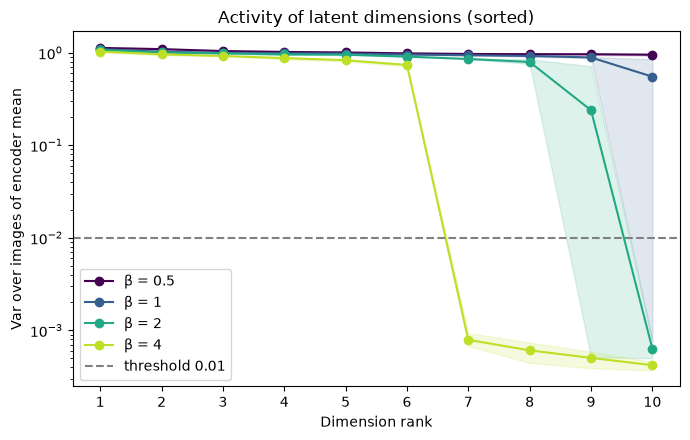

In [33]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for color, (b, var) in zip(colors, variances.items()):
    sorted_var = -np.sort(-var, axis=1)               # each seed sorted, largest first
    m = sorted_var.mean(axis=0)
    ranks = np.arange(1, len(m) + 1)
    ax.plot(ranks, m, "o-", color=color, label=f"β = {b}")
    if len(sorted_var) > 1:
        ax.fill_between(ranks, sorted_var.min(axis=0), sorted_var.max(axis=0), color=color, alpha=0.15)

ax.axhline(ACTIVE_THRESHOLD, color="gray", linestyle="--", label="threshold 0.01")
ax.set_yscale("log")
ax.set_xticks(ranks)
ax.set(title="Activity of latent dimensions (sorted)", xlabel="Dimension rank",
       ylabel="Var over images of encoder mean")
ax.legend()

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

fig.savefig(FIG_DIR / "active_units.pdf", bbox_inches="tight")


## 3. Latent traversals

For one validation image and the first seed of each selected β: one row per latent dimension, sorted from
most to least active. Each row varies that dimension from −3 to 3 while keeping the others at the
image's code. Inactive dimensions (variance below 0.01) are marked; their rows should barely change.

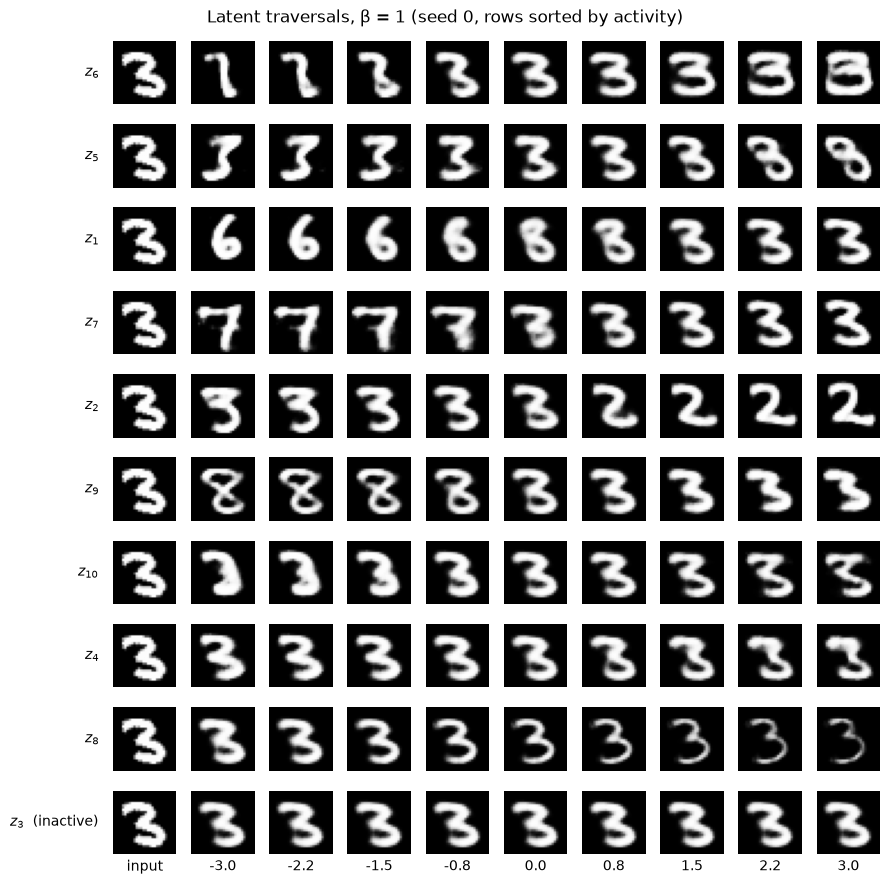

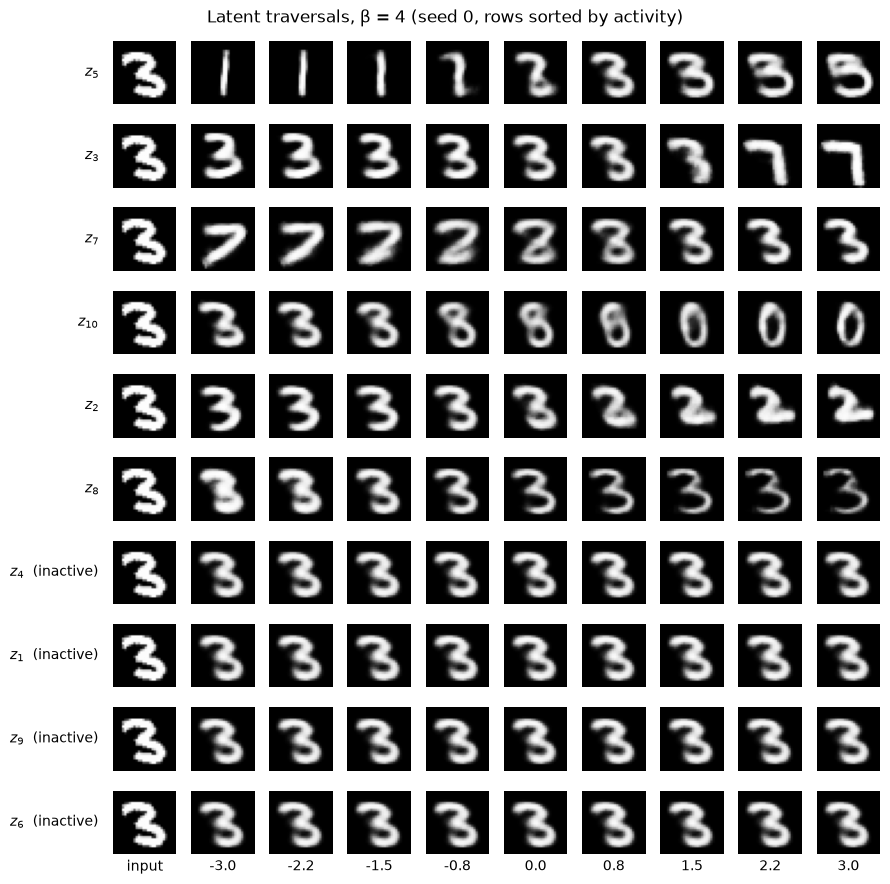

In [8]:
traversal_betas = ["1", "4"]                          # which β values to show
image_index = 0
values = np.linspace(-3, 3, 9)

for b in traversal_betas:
    run = seed_dirs(experiments[b])[0]
    model, _ = load_model(run)
    var = variances[b][0]                             # first seed's activity
    order = np.argsort(-var)                          # most active first

    z = encode(model, val_images[image_index:image_index + 1])   # (1, d)
    d = z.shape[1]
    fig, axes = plt.subplots(d, len(values) + 1, figsize=((len(values) + 1) * 0.9, d * 0.9))

    for row, j in enumerate(order):
        zs = z.repeat(len(values), 1)
        zs[:, j] = torch.as_tensor(values, dtype=zs.dtype)
        imgs = to_image(model.decoder(zs))
        axes[row, 0].imshow(to_image(val_images[image_index:image_index + 1])[0], cmap="gray", vmin=0, vmax=1)
        for k in range(len(values)):
            axes[row, k + 1].imshow(imgs[k], cmap="gray", vmin=0, vmax=1)
        mark = "" if var[j] > ACTIVE_THRESHOLD else "  (inactive)"
        axes[row, 0].set_ylabel(f"$z_{{{j + 1}}}${mark}", rotation=0, ha="right", va="center", labelpad=10)

    for ax in axes.flat:
        clean_axes(ax)
    axes[-1, 0].set_xlabel("input")
    for k, v in enumerate(values):
        axes[-1, k + 1].set_xlabel(f"{v:.1f}")
    fig.suptitle(f"Latent traversals, β = {b} (seed 0, rows sorted by activity)")

    plt.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.show()

## Save

In [9]:
pdf.close()
print("saved", FIG_DIR / "d3_beta_sweep.pdf", "and", FIG_DIR / "d3_active_units.csv")

saved /Users/Jeremie/Postdoc/representation_learning/vae_mnist/figures/d3_beta_sweep.pdf and /Users/Jeremie/Postdoc/representation_learning/vae_mnist/figures/d3_active_units.csv
